<a href="https://colab.research.google.com/github/ecmwf-projects/mooc-machine-learning-weather-climate/blob/main/tier_2/physic_informed/Physically_constrained_postprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 1: Physically-Constrained Post-Processing

⛈ Welcome to the first exercise of the "Physics-Guided Machine Learning" e-learning module of ECMWF's MOOC on Machine Learning in Weather and Climate 🌤

By the end of this first exercise, you will:

1.   Understand how constraining a machine learning model's output using physical knowledge can make it more consistent and trustworthy,
2.   Know how to use *custom layers* to enforce general nonlinear constraints within a neural network, and
3.   Practice what you learned about post-processing in Tier 1 on a real-world application case. 



While this notebook's completion time may widely vary depending on your programming experience, we estimate it will take a minimum of 30 minutes and much longer if you decide to explore the source code. This notebook provides a minimal reproducible example of the work described in the following preprint:

[Zanetta, Francesco, Daniele Nerini, Tom Beucler, and Mark A. Liniger. "Physics-constrained deep learning postprocessing of temperature and humidity."](https://arxiv.org/abs/2212.04487), 

and relies on the more general physically-constrained framework described in the following preprint: 

[Beucler, T., M. Pritchard, S. Rasp, P. Gentine, J. Ott, and P. Baldi. "Enforcing analytic constraints in neural-networks emulating physical systems."](https://arxiv.org/abs/1909.00912)

We provide an anonymized sample of our data. This pedagogical exercise would not have been possible without the source code and contribution of [Francesco Zanetta (MeteoSwiss, ETH)](https://github.com/frazane). 

We will be relying on PyTorch, whose documentation you can find [here](https://pytorch.org/), and the notebooks assume that you will run them on Google Colab (Google Colab tutorial [at this link](https://colab.research.google.com/github/ecmwf-projects/mooc-machine-learning-weather-climate/blob/main/tier_2/physic_informed/Physically_constrained_postprocessing.ipynb)). 

While everything can be run locally and there are only a handful of lines that use Google specific libraries, we encourage beginners to use Google Colab not to run into [Python virtual environment](https://docs.python.org/3/tutorial/venv.html) issues. 

Before we get started, if you are struggling with some of the exercises, do not hesitate to:


*   Use a direct Internet search, or [stackoverflow](https://stackoverflow.com/)
*   Debug your program, e.g. by following [this tutorial](https://swcarpentry.github.io/python-novice-inflammation/11-debugging/index.html)
*   Use assertions, e.g. by following [this tutorial](https://swcarpentry.github.io/python-novice-inflammation/10-defensive/index.html)
*   Ask for help on the MOOC's Moodle Forum

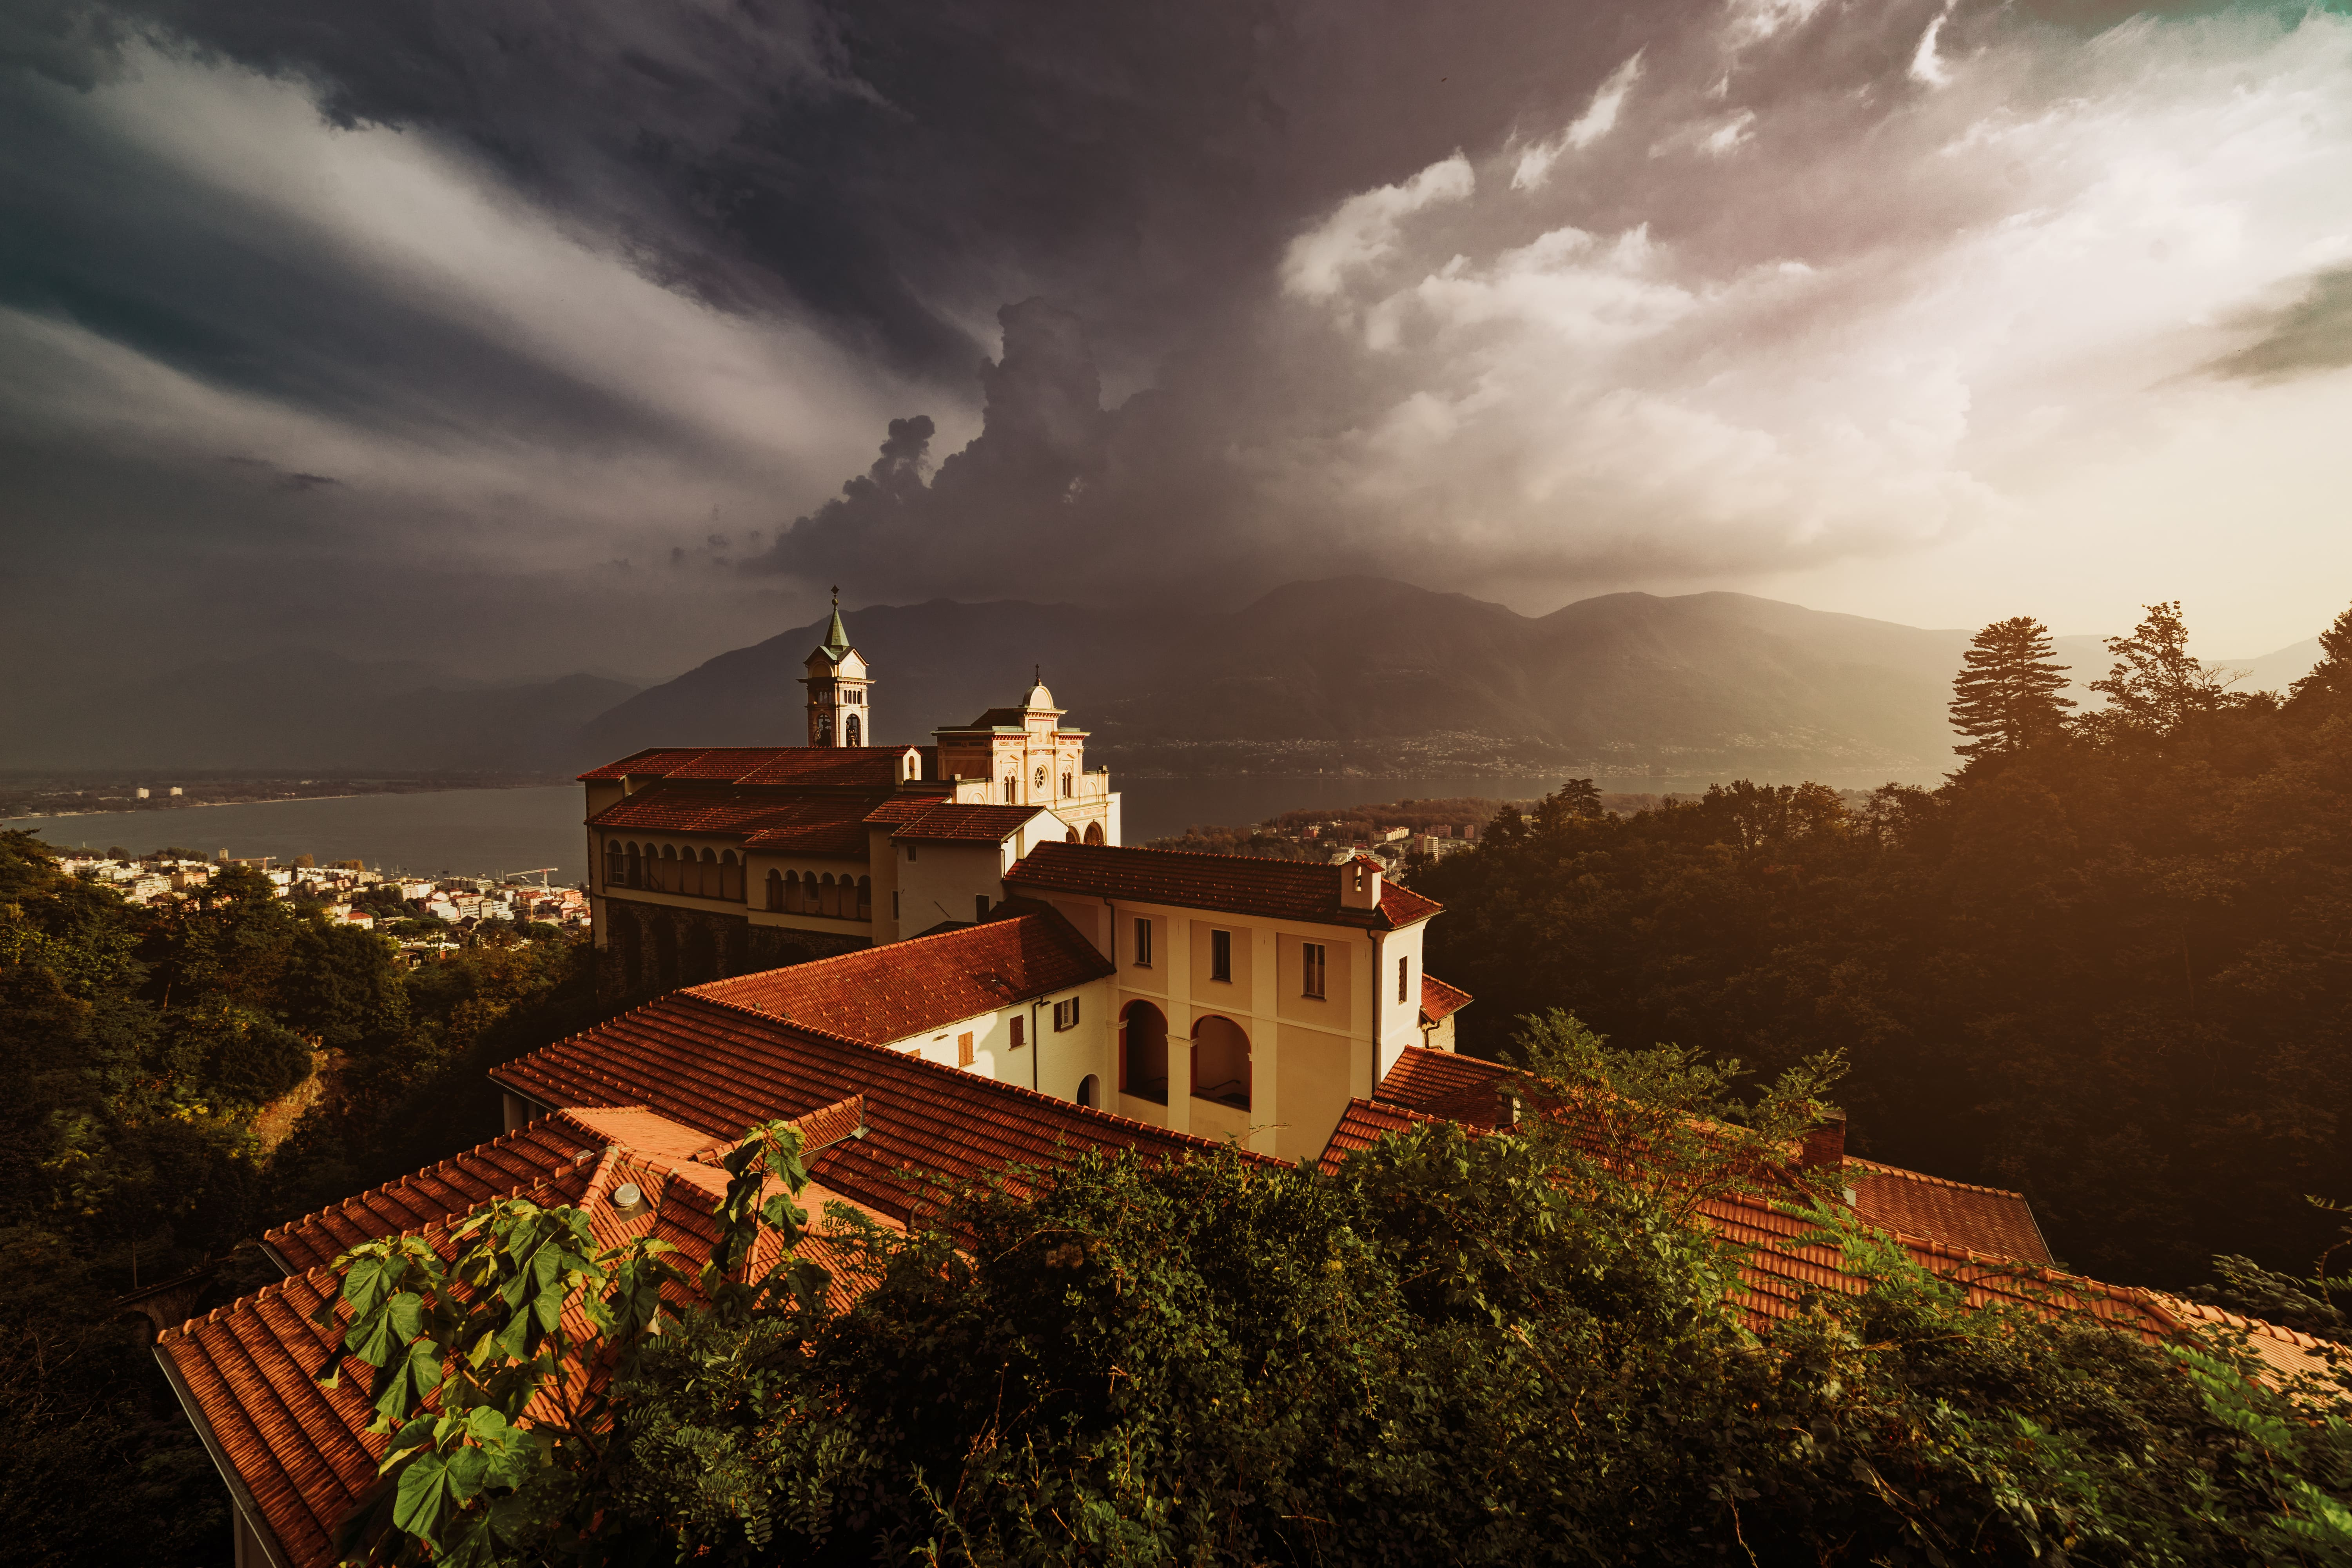

🌧 A storm is quickly approaching the [MeteoSwiss](https://www.meteoswiss.admin.ch/) agency in Locarno! Will you be able to post-process the weather it brings without violating the laws of thermodynamics? 🌡

*Source: Photo by [Marcell Faber](https://stock.adobe.com/ch_de/contributor/206314229/marcell-faber?load_type=author&prev_url=detail) licensed under the [Adobe Stock standard license](https://stock.adobe.com/license-terms)* 

## Part I. Configuration and requirements

In [ ]:
#@title  Run this cell for preliminary requirements. Double click for the source code
!sudo apt-get update -y
!sudo apt-get install python3.10
!sudo update-alternatives --install /usr/bin/python3 python3 /usr/bin/python3.7 1
!sudo update-alternatives --install /usr/bin/python3 python3 /usr/bin/python3.10 2
!curl https://bootstrap.pypa.io/get-pip.py -o get-pip.py
!python3 get-pip.py --force-reinstall
!python3 -m pip install ipython ipython_genutils ipykernel jupyter_console prompt_toolkit httplib2 astor
!ln -s /usr/local/lib/python3.7/dist-packages/google \
       /usr/local/lib/python3.10/dist-packages/google

!pip install numpy torch xarray==2022.10.0 netcdf4

In [ ]:
#@title  Run this cell for Python library imports. Double click for the source code
from itertools import chain

import os
import pooch
import numpy as np 
import xarray as xr
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from torch import optim

torch.manual_seed(1)
np.random.seed(1)

In [ ]:
#@title Run this cell to automatically save figures at the right place. Double click for the source code
# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=16)
mpl.rc('xtick', labelsize=14)
mpl.rc('ytick', labelsize=14)

# Where to save the figures
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "postprocessing"
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

In [ ]:
#@title  Run this cell to load the data using the pooch library. Double click for the source code

path_data = 'https://unils-my.sharepoint.com/:u:/g/personal/tom_beucler_unil_ch/'

# load training data 
x_path = path_data + 'EdAG3RBBgk5Kmvo54RPgT2kBp-NJqqGF6Il-gTmh9DbdeA?download=1'
y_path = path_data + 'EdVQCVKqnb9Bh495opeuRCEBBZFPDdG0g3xSpIFgNGJeJA?download=1'
x_open = pooch.retrieve(x_path,known_hash='c6acaf62051b81dfd3d5a4aa516d545615fd2597c8c38f4db4e571a621201878')
y_open = pooch.retrieve(y_path,known_hash='6265a5f0272e5427c823b95725b8aabbc48a9a97d7554fd5732e6c4b480f3ab3')

# load saved model's weights and biases to optionally accelerate
# the notebook's completion
u_path = path_data + 'ERb1IhuBFfZAjgcAF8N6pikBWet4WBZtheh9zvOyH7QNUg?download=1'
u_open = pooch.retrieve(u_path, known_hash='9dfb659526fa686062057de77bcb2d14ca46fc11212e799e9a5ec7175679b756')
a_path = path_data + 'EQuCPW4q2ilFpFQSZz_UDXYBjR2ZRRcJCDFW-EbI_xWKGg?download=1'
a_open = pooch.retrieve(a_path, known_hash='c6930d908c21785217b20895e19dbf6ddf6cd312b95b331ba590e2267d03e6f4')
l_path = path_data + 'EVb6Gw0ri6JJsazJ6mxUMXUBm4ndfmMjoj0M9gdIPDkd3A?download=1'
l_open = pooch.retrieve(l_path, known_hash = 'ab7e9013631d29806a8f73fbf7275cb37ca3561cb0d0c532107ea00ae496b187')

# build pointers to the data in the notebook using Xarray
x = (
    xr.open_dataset(x_open)
    .set_coords(["forecast_reference_time","t", "station_id"])
    .set_xindex("forecast_reference_time")
    .to_array("var")
    .transpose("s","var")
)
y = (
    xr.open_dataset(y_open)
    .set_coords(["forecast_reference_time","t"])
    .set_xindex("forecast_reference_time")
    .to_array("var")
    .transpose("s","var")
)

## Part II. Pre-processing your data for deep learning

Following best machine learning practices, we recommend splitting your data into three folds:  


1.   A training set, which is used to optimize the trainable parameters (weights and biases) of your machine learning model,
2.   A validation set, which is used to optimize the hyperparameters of your machine learning model, and check for underfitting/overfitting,
3.   A test set, which is used for independent testing after the trainable parameters and hyperparameters have been optimized. 

To avoid correlations between each fold, we will split the data using non-overlapping time series. To be able to compare your results with ours, we encourage you to use the following (left-inclusive, right-exclusive, just like in Python) dates for the split:


1.   Training: Jan 1, 2017 to Dec 25, 2019
2.   Validation: Jan 1, 2020 to Dec 25, 2020
3.   Test: Jan 1, 2021 to Jan 1, 2022



💡 **For all questions, you can write your own code or complete the proposed code by replacing the underscores with the appropriate script**

### **Q1) Split your data into training, validation, and test sets** 

The data was loaded as an [Xarray](https://docs.xarray.dev/en/stable/) [DataArray](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.html). Assuming you executed all of Part I's code cells, the inputs were loaded in `x` and the outputs were loaded in `y`. We recommend:

1.   Assigning the training inputs to `train_x` and the training outputs to `train_y`
2.   Assigning the validation inputs to `val_x` and the validation outputs to `val_y`
3.   Assigning the test inputs to `test_x` and the test outputs to `test_y`


Hints: 

1.   You may want to check out the [coordinates](https://docs.xarray.dev/en/stable/user-guide/data-structures.html) of `x` and `y` by simply typing `x` or `y` in an empty code cell and executing it. 
2.   If you're confused on how to select an exact time-period, you can read up on [Xarray's time-series data](https://docs.xarray.dev/en/stable/user-guide/time-series.html)
3.   [Xarray's method `sel`](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.sel.html) allows you to select data based *labels* instead of *integers*. If you prefer to select data based on integers, you can use the [`isel`](https://docs.xarray.dev/en/stable/generated/xarray.Dataset.isel.html) method. 



In [ ]:
# Here's an empty code cell to look at the data, etc.
# You can add or remove code and text cells via the "Insert" menu

In [ ]:
train_sel = dict(___=slice(___,___))
val_sel = dict(___=slice(___,___))
test_sel = dict(___=slice(___,___))

train_x, train_y = x.___(train_sel), y.___(train_sel)
val_x, val_y = x.___(val_sel), y.___(val_sel)
test_x, test_y = x.___(___), y.___(___)

In [ ]:
#@title A possible solution for Q1
train_sel = dict(forecast_reference_time = slice("2017-01-01", "2019-12-25"))
val_sel = dict(forecast_reference_time = slice("2020-01-01", "2020-12-25"))
test_sel = dict(forecast_reference_time = slice("2021-01-01", "2022-01-01"))

train_x, train_y = x.sel(train_sel), y.sel(train_sel)
val_x, val_y = x.sel(val_sel), y.sel(val_sel)
test_x, test_y = x.sel(test_sel), y.sel(test_sel)

### **Q2) Explore your training data to gain intuition on the meteorological variables to post-process and their distributions**

You may use the built-in [Xarray histogram plotting method](https://docs.xarray.dev/en/stable/generated/xarray.plot.hist.html) to quickly visualize your `x_train` and `y_train` DataArrays. The code to complete gives you an example of how to visualize one variable, while the solution visualizes all features.

*   The `bins` argument sets the number of bins
*   The `alpha` argument sets the transparency (between 0 and 1)
*   The `color` argument sets the histogram's color (e.g., `k` for black and `b` for blue)


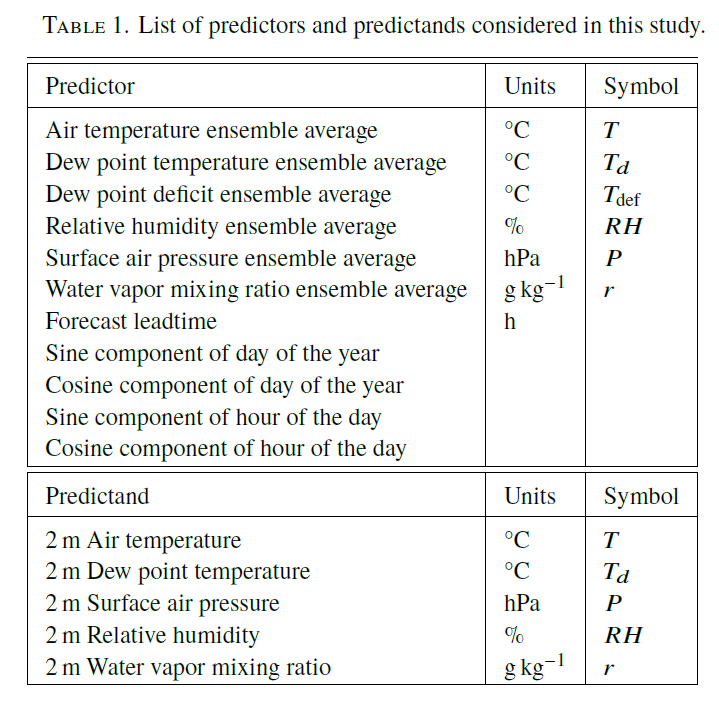

*List of predictors (or features or inputs) and predictands (or targets or outputs) used in this post-processing example*

Table 1 of [Zanetta et al. (2022)](https://arxiv.org/abs/2212.04487)

⚠ The predictor order in `train_x` is slightly different from Table 1's and given below:  
*   `coe:air_temperature_ensavg` = Air temperature ensemble average
*   `coe:dew_point_temperature_ensavg` = Dew-point temperature ensemble average
*   `coe:dew_point_depression_ensavg` = Dew-point depression ensemble average 
*   `coe:surface_air_pressure_ensavg` = Surface air pressure ensemble average
*   `coe:relative_humidity_ensavg` = Relative humidity ensemble average
*   `coe:water_vapor_mixing_ratio_ensavg` = Water vapor mixing ratio ensemble average
*   `coe:leadtime` = Forecast lead time
*   `time:cos_hourofday` = Cosine component of hour of the day
*   `time:sin_hourofday` = Sine component of hour of the day
*   `time:cos_dayofyear` = Cosine component of day of the year
*   `time:sin_dayofyear` = Sine component of the day of the year

In [ ]:
# Feel free to explore the data using this cell

In [ ]:
Nbin = ___ # Number of bins
fz = ___ # Fontsize

train_x[:,0].plot.hist(bins=___, alpha=___, color=___,
                       label='Forecast to Post-process (Feature)',
                       figsize=(15,5))
train_y[:,0].plot.hist(bins=___, alpha=___, color=___,
                        label='Observations (Target)')

plt.title('Air temperature (C)', fontsize=fz); 
plt.legend(fontsize=fz)

In [ ]:
#@title A possible solution for Q2
Nbin = 60 # Number of bins

# Loops over all features
for ix, xvar in enumerate(train_x['var']):
  # Plots the histogram of the feature in black 
  train_x[:,ix].plot.hist(bins=Nbin, alpha=0.5, color='k',
                          label='Forecast to Post-process (Feature)',
                          figsize=(15,2.5))
  
  # If the feature has a corresponding observation,
  # plots its histogram in blue
  iy = [iy for iy in range(len(train_y['var'])) if \
        str(train_y['var'][iy].values)[4:]==str(xvar.values)[4:-7]]
  if iy: train_y[:,iy].plot.hist(bins=Nbin, alpha=0.5, color='b',
                                 label='Observations (Target)')
  
  # Add one title per feature
  plt.title('Feature: '+str(xvar.values)[4:]); 
  plt.legend(fontsize=16)

### **Q3) Normalize your features** 
You may use a [standard normalization](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html). For each feature, it should set the training set-mean to 0 and the training set-standard deviation to 1. 

⚠ You can only use the training set to calculate your feature's statistical moments (mean, standard deviation, etc.); otherwise, you are at risk of validation/test [data leakage](https://en.wikipedia.org/wiki/Leakage_(machine_learning). 

💡 Given that we are running out-of-sample but not out-of-distribution tests in this notebook, this should also make the validation/test set-means close to 0 and the validation/test-standard deviations close to 1. 

Hints:



1.   Make sure you take the mean along the sample (`s`) dimension, which can be done by specifying the `axis` (an integer) or the name of the dimension `dim` (a string). 
2.   The standard normalization relies on the standard score or "Z-score", which you can read more about [at this link](https://en.wikipedia.org/wiki/Standard_score)
3.   The documentation for Xarray's DataArray's mean method is [here](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.mean.html) and that of the standard deviation method is [here](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.std.html). 



In [ ]:
# You can normalize your input data using the standard score
# by completing the code below
train_x_mean = train_x.___(___)
train_x_std = train_x.___(___)

train_x = (train_x - ___) / ___
val_x = (val_x - ___) / ___
test_x = (test_x - ___) / ___

In [ ]:
#@title A possible solution for Q3
train_x_mean = train_x.mean("s")
train_x_std = train_x.std("s")

train_x = (train_x - train_x_mean) / train_x_std
val_x = (val_x - train_x_mean) / train_x_std
test_x = (test_x - train_x_mean) / train_x_std

Below is code to:

*   Convert the Xarray [DataArrays](https://docs.xarray.dev/en/stable/generated/xarray.DataArray.html) `(train_x,train_y)` and `(val_x,val_y)` to Torch [Tensors](https://pytorch.org/docs/stable/tensors.html) versions of the training and validation data: `train` and `val`
*   Build your data generator (or data loader) for the training set `train_dl` and for the validation set `valid_dl` so that you can seemlessly feed the `train` and `valid` datasets to the neural networks you train. 

You can double click to check out the source code but we will not be focusing on the data generator in this notebook as it's fairly standard. 


In [ ]:
BATCH_SIZE = 1024 # You can choose your batch size here; we recommend 1024

In [ ]:
#@title Source code for Torch data loaders

class Data(Dataset):
    def __init__(self, x, y):

        self.x = torch.tensor(x.values).to("cuda:0")
        self.y = torch.tensor(y.values).to("cuda:0")
        self.station_id = torch.tensor(x.station_id.values, dtype=torch.int32).to("cuda:0")
        self.y_coords = y.coords

    def __len__(self):
        return self.x.shape[0]

    def __getitem__(self, idx):
        return (self.x[idx], self.station_id[idx]), self.y[idx]


class DataLoader(object):
    def __init__(self, dataset, batch_size, shuffle=False):
        self.dataset = dataset
        self.dataset_len = self.dataset.x.shape[0]
        self.batch_size = batch_size
        self.shuffle = shuffle
        n_batches, remainder = divmod(self.dataset_len, self.batch_size)
        if remainder > 0:
            n_batches += 1
        self.n_batches = n_batches

    def __iter__(self):
        if self.shuffle:
            r = torch.randperm(self.dataset_len)
            self.dataset.x = self.dataset.x[r]
            self.dataset.station_id = self.dataset.station_id[r]
            self.dataset.y = self.dataset.y[r]
        self.i = 0
        return self

    def __next__(self):
        if self.i >= self.dataset_len:
            raise StopIteration
        batch = self.dataset[self.i : self.i + self.batch_size]
        self.i += self.batch_size
        return batch

    def __len__(self):
        return self.n_batches

In [ ]:
# Convert Xarray training/validation DataArray to Torch Tensors
train = Data(train_x, train_y)
val = Data(val_x, val_y)

# Build training/validation data loaders
train_dl = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True)
val_dl = DataLoader(val, batch_size=BATCH_SIZE * 8)

## Part III. Physically-constrained neural network

Now comes the fun part! We are going to compare two methods to incorporate thermodynamic state equations (here, the ideal gas law and an integral of Clausius-Clapeyron) into neural networks post-processing surface weather 🌧



1.   A **loss-constrained** setting (d), in which the neural network is penalized for violating the laws of thermodynamics (soft constraint), and
2.   An **architecture-constrained** setting (c), in which the neural network is forced to follow the laws of thermodynamics (hard constraint). 
3.   We also use an **unconstrained** setting (b) for reference (baseline model).



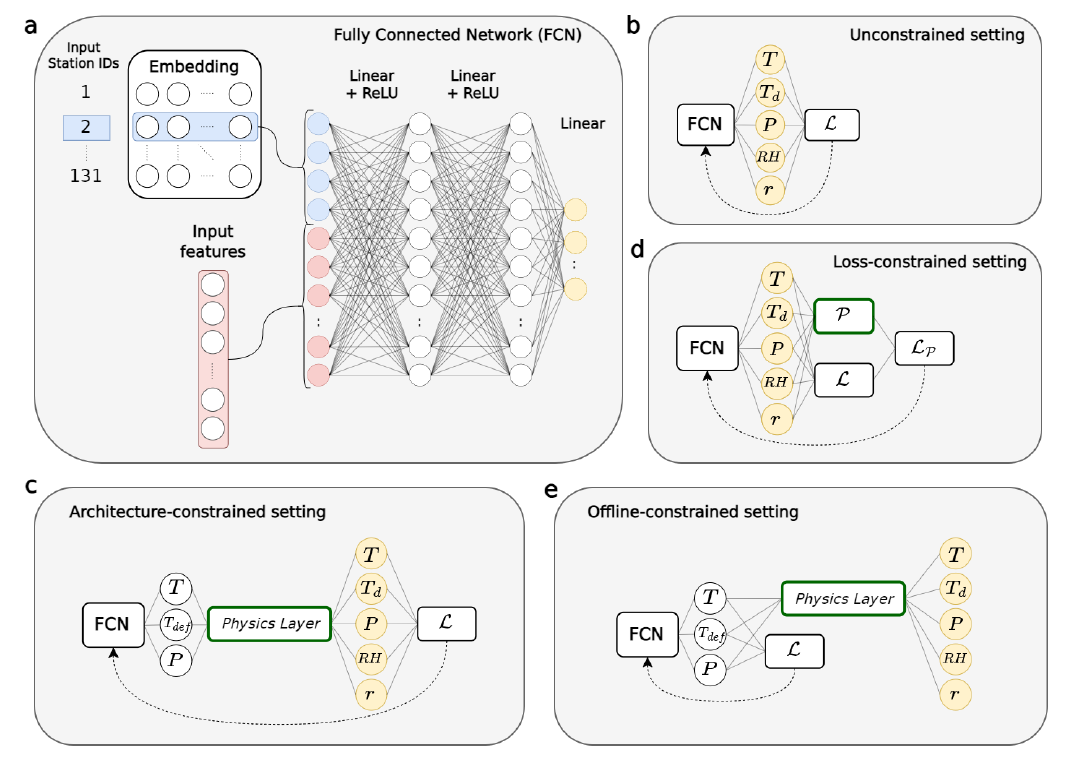

*Comparison of different ways of enforcing physical constraints in a neural network post-processing temperature (T), dew-point temperature ($T_d$), pressure (P), relative humidity (RH), and water vapor mixing ratio (r).*

Figure 2 of [Zanetta et al. (2022)](https://arxiv.org/abs/2212.04487)

### **Q4) Using the schematic above and the equations below, implement the physical constraints**

This layer should take in temperature, dew-point depression, and pressure, and output temperature, dew-point temperature, pressure, relative humidity, and water vapor mixing ratio. Here, we'll practice directly on the observations, which already follow the physical constraints.

**1) Dew-point temperature $T_{d}$** is related to the temperature T and the dew-point depression $T_{def}$ through its definition:

$T_{d} = T - T_{def}$

**2) Water vapor mixing ratio r** can be calculated as a function of pressure and dew-point temperature through the water vapor partial pressure, which can be approximated by integrating the Clausius-Clapeyron equation. Using the approximate integral used by MeteoSwiss, the water vapor partial pressure is given by: 

$e \left[ hPa \right] = c \times \exp \left( \frac {a T_{d}}{b+T_{d}} \right) $,

where $a\approx 17.368$, $b\approx238.83$, and $c\approx6.107$hPa for $T \geq 0$ and  
$a\approx 17.856$, $b\approx245.52$, and $c\approx6.108$hPa for $T < 0$.

Then, using the ideal gas law, we can calculate the water vapor mixing ratio [in g/kg] from the water vapor partial pressure $e$ and the total air pressure $p$ :

$r \left[g/kg\right] = 1000 \times 0.622 \times \frac{e}{p-e}$


**3) Relative humidity RH** is defined as the ratio of the water vapor partial pressure $e$ to its saturation value $e_{s}$:

$RH \left[\%\right] = 100 \times e/e_{s}$.

Note that saturation water vapor pressure can be calculated by substituting the dew-point temperature for its absolute value in the formula for water vapor partial pressure: 

$e_{s} \left[ hPa \right] = c \times \exp \left( \frac {a T}{b+T} \right) $

In [ ]:
# Assume we already have access to temperature, dew-point depression,
# and surface air pressure

temperature = train_y[:,0]
dewpoint_depression = temperature - train_y[:,1]
air_pressure = train_y[:,2]

In [ ]:
# Can you calculate water vapor mixing ratio and relative humidity? 
# You may fill out the code below
# and use numpy's where function 
# (https://numpy.org/doc/stable/reference/generated/numpy.where.html),
# which return values depending on conditions. 
# np.where is useful for the above version of the water vapor partial pressure, 
# which is defined based on the absolute temperature's sign. 

# 1) Calculate the dewpoint temperature
temperature_dp = ___ - ___

# 2) Calculate water vapor mixing ratio
wv_pressure = np.where(
    temperature >= 0.0,
    ___ * np.___((___) / (___)),
    ___ * np.___((___) / (___)),
    )
wv_mix_ratio = ___ * (___ / (___))

# 3) Relative humidity
wv_satpressure = ___.___(
    ___,
    ___,
    ___,
    )
relative_humidity = ___

In [ ]:
# Or use this empty cell

In [ ]:
#@title This cell should output a very small number (absolute value less than 1e-6) if you correctly implemented the physical constraints
print(f'1) The squared residual of the dew-point temperature is {np.mean((temperature_dp-train_y[:,1]).values):.1e} K^2')
print(f'2) The squared residual of the water vapor mixing ratio is {np.mean((wv_mix_ratio-train_y[:,4]).values):.1e} (g/kg)^2')
print(f'3) The squared residual of the relative humidity is {np.mean((relative_humidity-train_y[:,3]).values):.1e} (%)^2')

In [ ]:
#@title A possible solution for Q4

# 1) Calculate the dewpoint temperature
temperature_dp = temperature - dewpoint_depression

# 2) Calculate water vapor mixing ratio
wv_pressure = np.where(
    temperature >= 0.0,
    6.107 * np.exp((17.368 * temperature_dp) / (temperature_dp + 238.83)),
    6.108 * np.exp((17.856 * temperature_dp) / (temperature_dp + 245.52)),
    )
wv_mix_ratio = 622.0 * (wv_pressure / (air_pressure - wv_pressure))

# 3) Relative humidity
wv_satpressure = np.where(
    temperature >= 0.0,
    6.107 * np.exp((17.368 * temperature) / (temperature + 238.83)),
    6.108 * np.exp((17.856 * temperature) / (temperature + 245.52)),
    )
relative_humidity = 100.0 * wv_pressure / wv_satpressure

Converting our physical constraints to physically-constrained layers mostly requires several steps:

1.   Writing a custom `PhysicsLayers` class that inherits the properties of Torch's [base module class](https://pytorch.org/docs/stable/generated/torch.nn.Module.html), and
2.   Converting our physical constraints from standard Python/numpy to PyTorch, remembering that temperature, temperature deficit, and surface air pressure are direct outputs of the neural network and inputs of our physically-constrained layer.  

The `PhysicsLayer` below typically takes more time to implement than the 30 minutes we have for this notebook, so we directly give you its source code.

In [ ]:
#@title Source code for the physically-constrained layer: Run it to proceed, double click to see the code
class PhysicsLayer(nn.Module):
    def __init__(self):
        super(PhysicsLayer, self).__init__()

    def forward(self, direct):
        t, t_def, p = direct[:, 0], direct[:, 1], direct[:, 2]
        # Below, the rectified linear unit ensures the positivity of
        # the deficit temperature, which is not guaranteed when it is
        # a direct output of the neural network 
        t_d = t - torch.relu(t_def)
        e_s = torch.where(
            t >= 0.0,
            6.107 * torch.exp((17.368 * t) / (t + 238.83)),
            6.108 * torch.exp((17.856 * t) / (t + 245.52)),
        )
        e = torch.where(
            t >= 0.0,
            6.107 * torch.exp((17.368 * t_d) / (t_d + 238.83)),
            6.108 * torch.exp((17.856 * t_d) / (t_d + 245.52)),
        )
        rh = e / e_s * 100.0
        r = 622.0 * (e / (p - e))
        pred = torch.stack([t, t_d, p, rh, r], dim=1)
        return pred

Additionally, below is the source code for all of our neural networks' architectures, which are wrapped in the `Net` class. In this class, we initialize the output bias manually to values that are in the same order of magnitude as our targets to facilitate training. Optionally, if the `constraint` argument is set to `True`, the architecture may include the `PhysicsLayer` encoding the physical constraints.

In [ ]:
#@title Source code for the neural networks' architectures' wrapper class: Run it to proceed, double click to see the code
class Net(nn.Module):

    # Initialize the biases with mean value for each variable to facilitate learning
    out_bias = [15.0, 10.0, 900.0, 70.0, 5.0]  # t, t_d, p, rh, r
    out_bias_constrained = [15.0, 5.0, 900]  # t, t_def, p

    # Initializes the neural network architecture
    def __init__(self, in_size, n_stations, embedding_size, l1, l2, constraint=False):
        super(Net, self).__init__()
        self.embedding = nn.Embedding(n_stations, embedding_size)
        self.l1 = nn.Linear(in_size + embedding_size, l1)
        self.l2 = nn.Linear(l1, l2)
        # Physically-constrained version
        if constraint:
            self.out = nn.Sequential(nn.Linear(l2, 3), PhysicsLayer())
            self.out[0].bias = nn.Parameter(torch.Tensor(self.out_bias_constrained))
        # Unconstrained version
        else:
            self.out = nn.Linear(l2, 5)
            self.out.bias = nn.Parameter(torch.Tensor(self.out_bias))

    # Defines a forward pass through the neural network
    def forward(self, x, station_id):
        station_embedding = self.embedding(station_id)
        x = torch.concat([x, station_embedding], dim=-1)
        x = torch.relu(self.l1(x))
        x = torch.relu(self.l2(x))
        out = self.out(x)
        return out

## Part IV. Multi-task loss function

Even in the unconstrained case, our loss function is *multi-task* because it optimizes the post-processing of multiple variables (mixing ratio, relative humidity, etc.). Choosing how to weigh different terms of the loss function when a regression has multiple outputs with different units and uncertainties is tricky and time-consuming 😖

Therefore, we follow the multi-task framework of: 

[Kendall, A., Gal, Y., & Cipolla, R. (2018). Multi-task learning using uncertainty to weigh losses for scene geometry and semantics. In Proceedings of the IEEE conference on computer vision and pattern recognition (pp. 7482-7491).](https://arxiv.org/abs/1705.07115)

and weigh each term of the loss function by a learned uncertainty term, which is not allowed to set the term to zero (even if it's hard to learn!). We refer you to the paper above for the mathematical details, summarized in section 2c of [Zanetta et al.'s preprint](https://arxiv.org/abs/2212.04487).

Below, we define the `MultiTaskLoss` class to implement this uncertainty-weighted loss function, and optionally adds the physics-based loss term computed with `physical_penalty`. This term balances performance and physical consistency using a hyperparameter $\alpha$:

$loss = (1 - \alpha) \times (multi-task\ loss) + \alpha \times (physics\ loss)$


In [ ]:
#@title Source code for the multitask loss: Run it to proceed, double click to see the code
class MultiTaskLoss(nn.Module):
    def __init__(self, alpha=0.0, mask=None, log_var_init=None):
        super(MultiTaskLoss, self).__init__()
        self.alpha = alpha
        self.mask = [True] * 5 if mask is None else mask

        log_var = torch.zeros(5) if log_var_init is None else log_var_init

        self.log_var = nn.Parameter(log_var)

        self.hp = {"alpha": alpha}

    def forward(self, pred, y):
        loss = torch.mean((pred - y) ** 2, axis=0)
        loss = torch.exp(-self.log_var) * loss + self.log_var
        loss = torch.sum(loss[self.mask])
        rh_res, r_res = physical_penalty(pred)
        physics_loss = rh_res / torch.var(y[:, 3]) + r_res / torch.var(y[:, 4])
        if self.alpha > 0.0:
            loss = (1 - self.alpha) * loss + self.alpha * physics_loss
        return loss, physics_loss


def physical_penalty(pred):
    t, t_d, p, rh, r = pred[:, 0], pred[:, 1], pred[:, 2], pred[:, 3], pred[:, 4]
    e = torch.where(
        t >= 0.0,
        6.107 * torch.exp((17.368 * t_d) / (t_d + 238.83)),
        6.108 * torch.exp((17.856 * t_d) / (t_d + 245.52)),
    )
    e_s = torch.where(
        t >= 0.0,
        6.107 * torch.exp((17.368 * t) / (t + 238.83)),
        6.108 * torch.exp((17.856 * t) / (t + 245.52)),
    )
    rh_derived = e / (e_s + 1e-5) * 100.0
    r_derived = 622.0 * (e / (p - e))

    return (
        torch.mean((rh_derived - rh) ** 2),
        torch.mean((r_derived - r) ** 2),
    )

## Part V. Model training

In [ ]:
LR = 0.0008 # Define your learning rate here (recommended = 8e-4)

In [ ]:
#@title Source code for the training/validation functions: Run it to proceed, double click to see the code

def training_step(model, loss_fn, optimizer, train_dataloader):
    model.train(True)
    loss_fn.train(True)
    running_loss = 0.0
    num_batches = len(train_dataloader)
    iterator = enumerate(train_dataloader)
    for i, (X, y) in iterator:
        pred = model(*X)
        loss, p = loss_fn(pred, y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    return running_loss / num_batches


def validation_step(model, loss_fn, val_dataloader):
    model.train(False), loss_fn.train(False)
    val_loss = 0.0
    val_p = 0.0
    val_mae = 0.0
    with torch.no_grad():
        iterator = val_dataloader
        for X, y in iterator:
            pred = model(*X)
            loss, p = loss_fn(pred, y)
            val_loss += loss.item()
            val_p += p.item()
            val_mae += torch.mean(torch.abs(pred - y), dim=0)
    val_loss /= len(val_dataloader)
    val_p /= len(val_dataloader)
    val_mae /= len(val_dataloader)
    return val_loss, val_p, val_mae


def fit(model, loss_fn, train_dl, val_dl, max_epochs=20, max_patience=5):
    optimizer = optim.Adam(
        chain(model.parameters(), loss_fn.parameters()), lr=LR
    )
    best_val_nmae = torch.inf
    val_y_std = val.y.std(dim=0)
    for epoch in range(max_epochs):

        train_loss = training_step(model, loss_fn, optimizer, train_dl)
        val_loss, val_p, val_mae = validation_step(model, loss_fn, val_dl)
        val_nmae = torch.mean((val_mae / val_y_std))

        if val_nmae < best_val_nmae:
            best_val_nmae = val_nmae
            best_model = model
            patience = 0
        else:
            patience += 1
            if patience == max_patience:
                break

        print(
            f"{epoch+1:<2}{'':>4}loss: {train_loss:<10.4}val_loss: {val_loss:<10.4}"
            f"val_t_mae: {val_mae[0]:<10.4} val_rh_mae: {val_mae[3]:<10.4}"
            f"val_nmae: {val_nmae:<10.4} val_p: {val_p:<10.4}"
        )

    return best_model

In [ ]:
torch.device("cuda:0") # Enables GPU runtime in Google Colab

### **Q5) Train three neural networks: unconstrained, architecture-constrained, and loss-constrained.**

Note: The training may take very long and can easily exceed 30 minutes per network if you use more than 15 epochs. Therefore, we provide trained model after Q5's solution.  

Hints:



1.   You can instantiate a neural network using the `Net` class we defined above, and which takes the following argument:
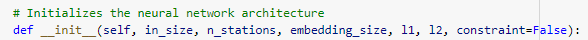





*   `in_size`: The input size (here we have 11 features from the NWP model)
*   `n_stations`: The number of stations (here 131)
*   `embedding_size`: The embedding size, which you can read more about [here](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html)
*   `l1`: The number of units in layer 1 (and **NOT** the L1 regularization coefficient)  
*   `l2`: The number of units in layer 2 (and **NOT** the L2 regularization coefficient)
*   `constraint`: A boolean defining whether a physics-constraint layer is used or not

2.   After defining the loss, you may use the `fit` function defined above:   

image.png

`fit` takes the following arguments: 



*   `model`: The machine learning model to train
*   `loss_fn`: The loss function
*   `train_dl`: The training data loader
*   `val_dl`: The validation data loader
*   `max_epochs`: The maximal number of epochs  
*   `patience`: The patience (how many epochs we wait until stopping the training if the validation loss does not improve)

Note that as you fit your neural network, the function will provide the following diagnostics:

*   `loss`: The value of the loss function you chose, averaged over the training set   
*   `val_loss`: The value of the loss function you chose, averaged over the validation set
*   `val_t_mae`: The mean absolute error of the temperature (in K) over the validation set
*   `val_rh_mae`: The mean absolute error of the relative humidity (in %) over the validation set
*   `val_nmae`: The normalized mean absolute error (using the standard deviation of each variable to normalize its MAE) over the validation set
*   `val_p`: The **physical violation term**, i.e., the residual from the thermodynamic state equations, averaged over the validation set. 

In [ ]:
# Define your hyperparameters here
# We give the recommended value for each hyperparameter below

ALPHA = 0.995 # Recommended for the loss-constrained neural networks
# The hyperparameters below are recommended across models
EMBEDDING_SIZE=5
MAX_EPOCHS = 20 # 10-15 to finish notebook on time but at least 20 for performance
N_INPUTS = 11
N_STATIONS = 131
PATIENCE = 5
UNITS_L1 = 128
UNITS_L2 = 256

In [ ]:
# Uncomment below to use multiple threads
# torch.set_num_threads(2)

In [ ]:
# Unconstrained neural network: Definition
unconstrained_NN = Net(
    ___, ___, ___, ___, ___, constraint=___
    ).to("cuda:0")
loss = MultiTaskLoss(alpha=___).to("cuda:0")

In [ ]:
# Unconstrained neural network: Training
unconstrained_NN = fit(unconstrained_NN, loss, train_dl, val_dl, 
                       max_epochs=___,
                       patience=___)

In [ ]:
# Architecture-constrained neural network: Definition
architecture_constrained_NN = Net(
    ___, ___, ___, ___, ___, ___
    ).to("cuda:0")
loss = MultiTaskLoss(___).to("cuda:0")

In [ ]:
# Architecture-constrained neural network: Training
architecture_constrained_NN = fit(___, ___, 
                                  ___, ___,
                                  ___,
                                  ___)

In [ ]:
# Loss-constrained neural network: Definition
loss_constrained_NN = Net(
    ___, ___, ___, ___, ___, ___
    ).to("cuda:0")
constrained_loss = ___(___).to("cuda:0")

In [ ]:
# Loss-constrained neural network: Definition
loss_constrained_NN = ___(___, ___,
                          ___, ___,
                          ___,
                          ___)

In [ ]:
#@title A possible solution for Q5 (1/3)

torch.set_num_threads(2)

# Unconstrained neural network
unconstrained_NN = Net(
    N_INPUTS, N_STATIONS, EMBEDDING_SIZE, UNITS_L1, UNITS_L2, constraint=False
    ).to("cuda:0")
loss = MultiTaskLoss(alpha=0.0).to("cuda:0")

unconstrained_NN = fit(unconstrained_NN, loss, train_dl, val_dl, 
                       max_epochs=MAX_EPOCHS,
                       patience=PATIENCE)

In [ ]:
#@title A possible solution for Q5 (2/3)

# Architecture-constrained neural network
architecture_constrained_NN = Net(
    N_INPUTS, N_STATIONS, EMBEDDING_SIZE, UNITS_L1, UNITS_L2, constraint=True
    ).to("cuda:0")
loss = MultiTaskLoss(alpha=0.0).to("cuda:0")

architecture_constrained_NN = fit(architecture_constrained_NN, loss, 
                                  train_dl, val_dl,
                                  max_epochs=MAX_EPOCHS,
                                  patience=PATIENCE)

In [ ]:
#@title A possible solution for Q5 (3/3)

# Loss-constrained neural network
loss_constrained_NN = Net(
    N_INPUTS, N_STATIONS, EMBEDDING_SIZE, UNITS_L1, UNITS_L2, constraint=False
    ).to("cuda:0")
constrained_loss = MultiTaskLoss(alpha=ALPHA).to("cuda:0")

loss_constrained_NN = fit(loss_constrained_NN, constrained_loss,
                          train_dl, val_dl,
                          max_epochs=MAX_EPOCHS,
                          patience=PATIENCE)

In [ ]:
#@title If you are running out of time, we provide the weights and biases of trained models, which you may directly load by running the cell below

# Unconstrained neural network. Using a different name to prevent overwriting.
unconstrained_NN_provided = Net(
    N_INPUTS, N_STATIONS, EMBEDDING_SIZE, UNITS_L1, UNITS_L2, constraint=False
    ).to("cuda:0")
unconstrained_NN_provided.load_state_dict(torch.load(u_open))

# For more custom models, load the entire model instead of the state_dict
# Architecture-constrained neural network. Using a different name to prevent overwriting.
architecture_constrained_NN_provided = torch.load(a_open)

# Loss-constrained neural network. Using a different name to prevent overwriting.
loss_constrained_NN_provided = Net(
    N_INPUTS, N_STATIONS, EMBEDDING_SIZE, UNITS_L1, UNITS_L2, constraint=False
    ).to("cuda:0")
loss_constrained_NN_provided.load_state_dict(torch.load(l_open))

Note: The models that are already trained use different names to avoid overwriting the models you trained: 



*   `unconstrained_NN_provided` for the unconstrained neural network
*   `architecture_constrained_NN_provided` for the architecture-constrained neural network
*   `loss_constrained_NN_provided` for the loss-constrained neural network



## Part VI. Model evaluation

In [ ]:
# Convert the test dataset to Torch
test = Data(test_x, test_y)

# Build a test data loader/generator
test_dl = DataLoader(test, batch_size=BATCH_SIZE * 16)

In [ ]:
#@title Source code for the mode evaluation function
def evaluate(model, test_dl):
    model.eval()
    mae = 0.0
    with torch.no_grad():
        iterator = test_dl
        for X, y in iterator:
            pred = model(*X)
            mae += torch.mean(torch.abs(pred - y), dim=0)
    return mae / len(test_dl) 

### **Q6) Evaluate the performance and physical consistency of each neural network type** (unconstrained, architecture-constrained, and loss-constrained).  

What are the benefits and drawbacks of each architecture/loss?

Hint: You may call the `evaluate` function, which takes two arguments: 



1.   The machine learning model `model`
2.   The data loader of the dataset you would like to use for evaluation. 

It outputs the mean absolute error for each target variable: air temperature, dew point temperature, surface air pressure, relative humidity, and water vapor mixing ratio. 

In [ ]:
# Evaluate the unconstrained network
evaluate(___, ___)

In [ ]:
# Evaluate the architecture-constrained network
evaluate(___, ___)

In [ ]:
# Evaluate the loss-constrained network
evaluate(___, ___)

In [ ]:
print()

In [ ]:
#@title A possible solution for Q6
print('The unconstrained NN performance is:')
print(evaluate(unconstrained_NN, test_dl),'\n')

print('The architecture-constrained NN performance is:')
print(evaluate(architecture_constrained_NN, test_dl),'\n')

print('The loss-constrained NN performance is:')
print(evaluate(loss_constrained_NN, test_dl),'\n')

print('The raw performance of the unconstrained NN can be slightly better ')
print('than the raw performance of the architecture-constrained NN.\n')

print('However, this comes at the cost of physical consistency as ')
print('the unconstrained NN takes "shortcuts" and violates physical laws.\n')

print('Architecture-constrained NNs enforce thermodynamic state equations')
print('to within machine precision without a noticeable trade-off in performance.\n')

print('Loss-constrained NNs are easy to implement but it can be difficult ')
print('to choose the right value for the hyperparameter alpha, as ')
print('the loss-constrained implementation always leads to ')
print('a trade-off between performance and physical consistency.')

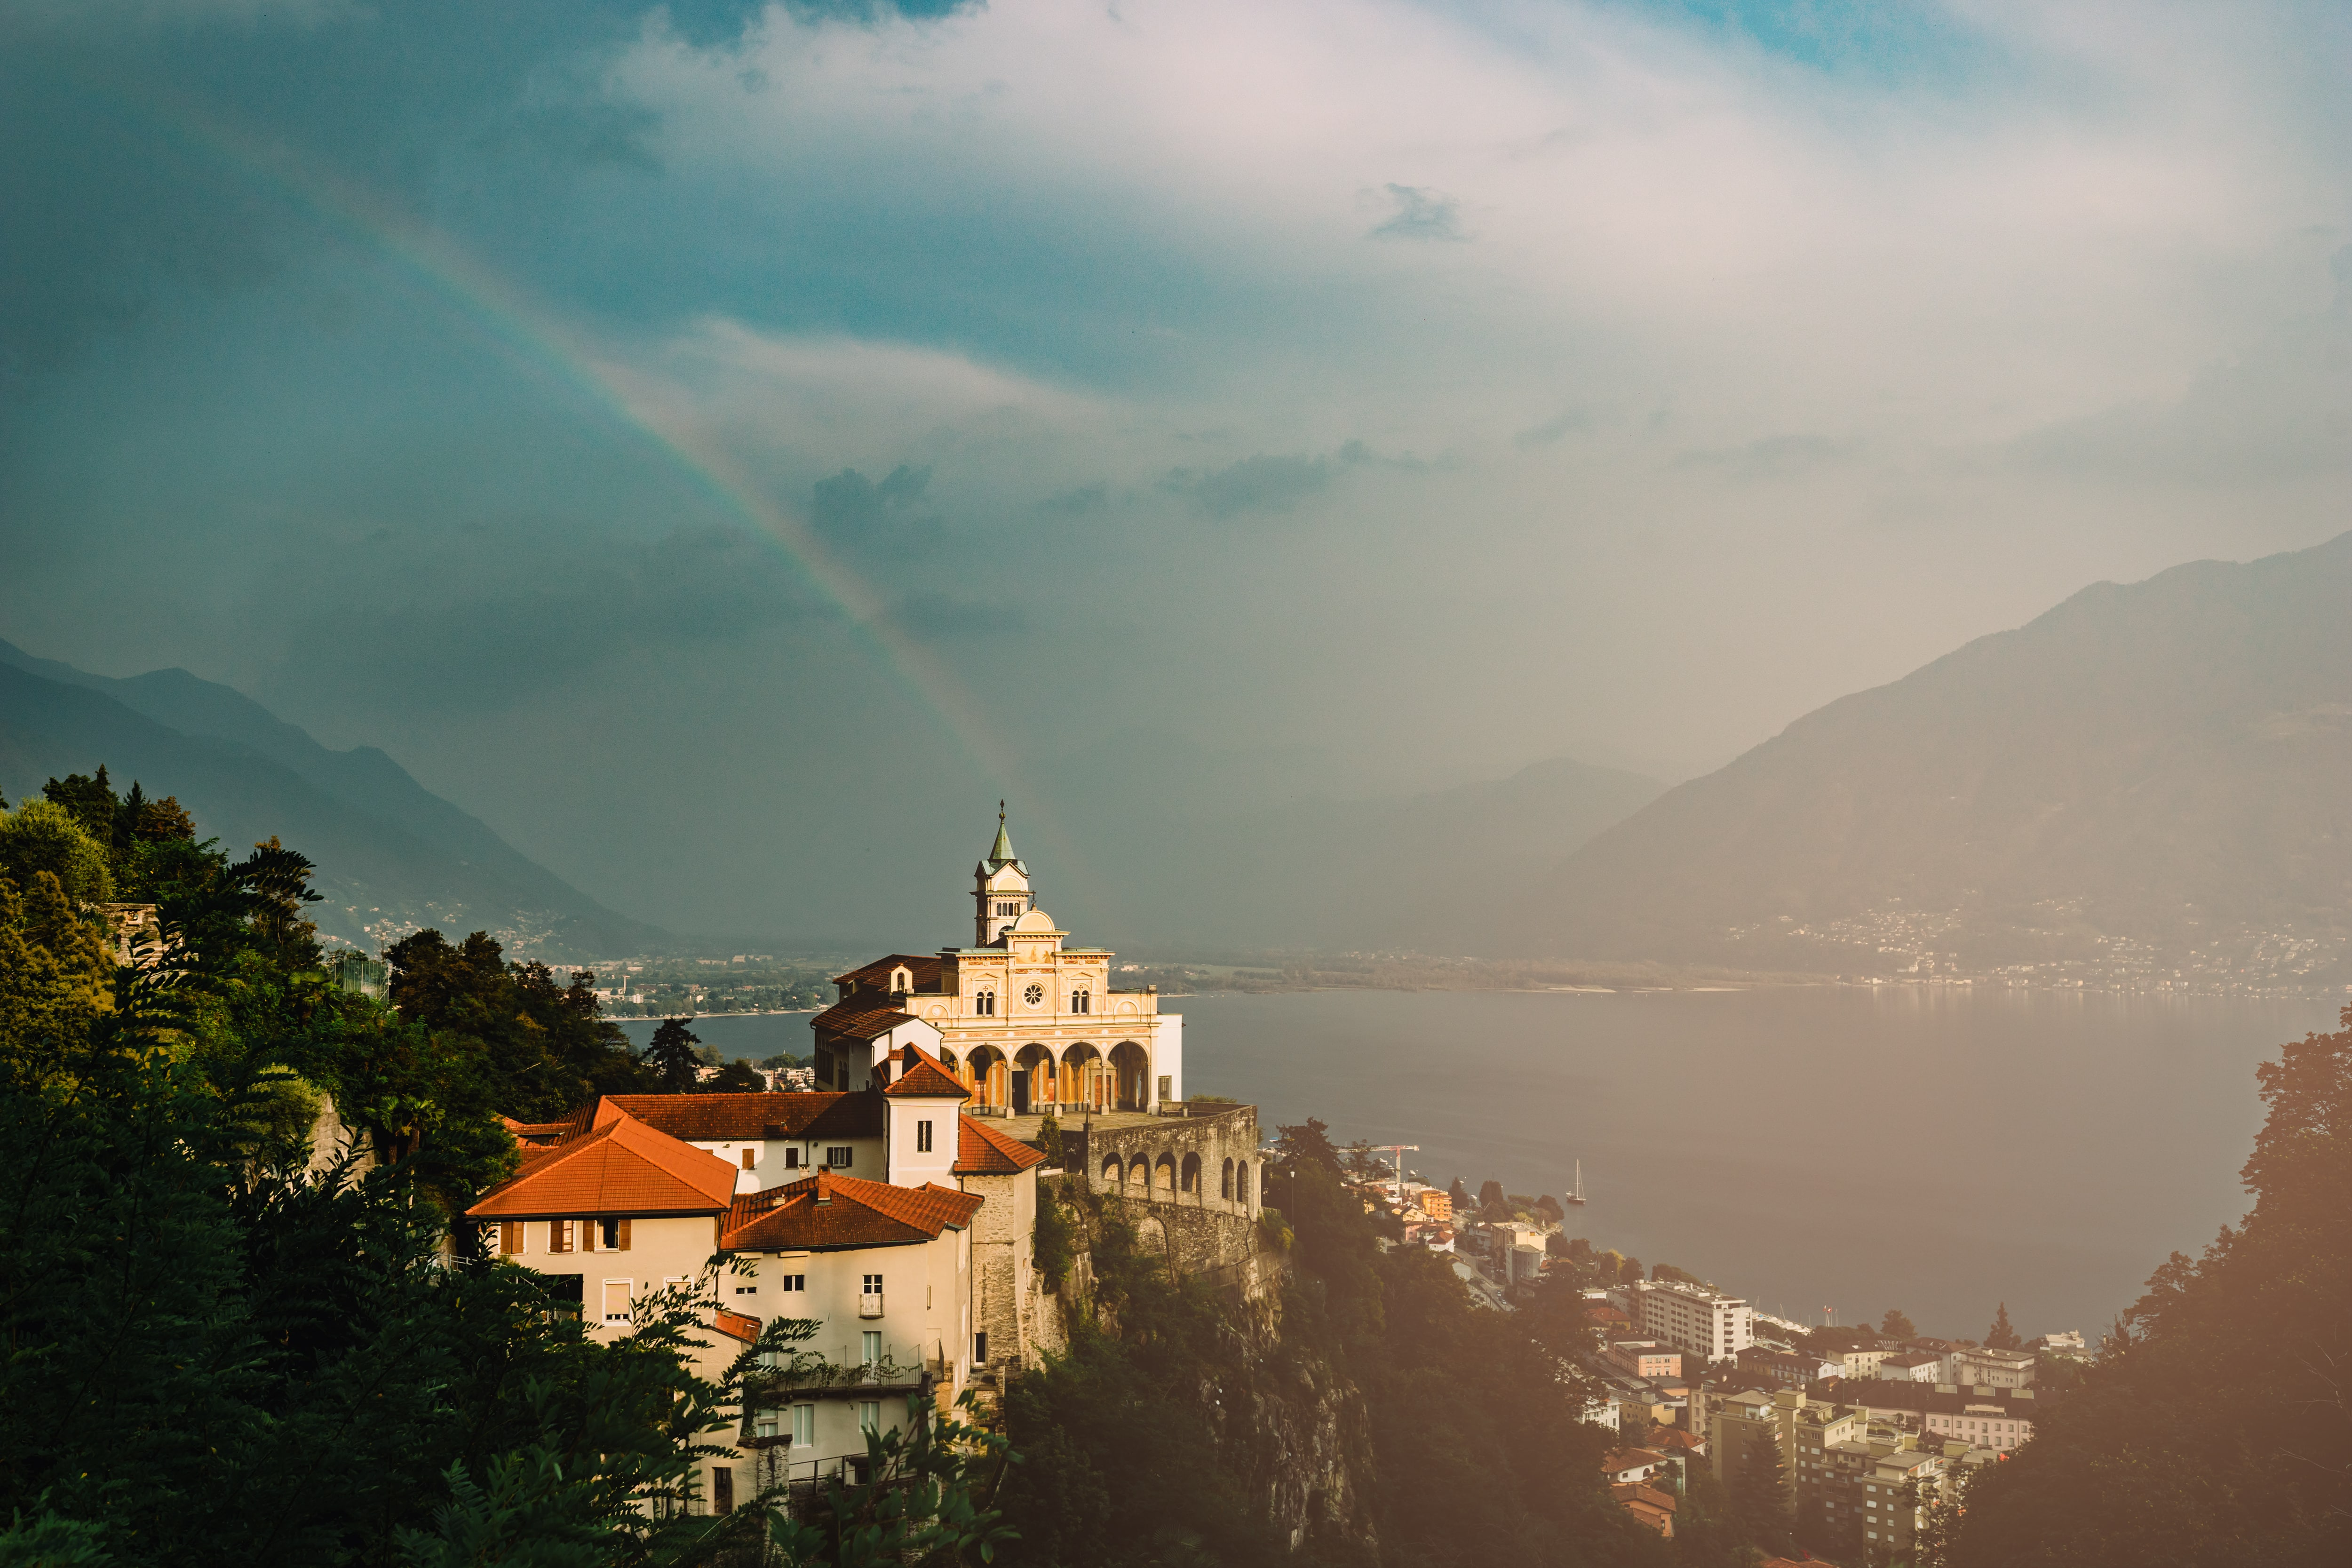

🌈 Phew, after your successful physically-constrained, deep learning forecast, the storm is over. But hopefully, your quest for knowledge isn't 📚 Stay tuned for this session's second exercise, in which you will learn how to use physical knowledge, this time to make a neural network generalize over vastly different climates!

*Source: Photo by [Marcell Faber](https://stock.adobe.com/ch_de/contributor/206314229/marcell-faber?load_type=author&prev_url=detail) licensed under the [Adobe Stock standard license](https://stock.adobe.com/license-terms)* 